In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython import display
display.set_matplotlib_formats('svg')

/tmp/ipykernel_3486/2026922495.py:6: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  display.set_matplotlib_formats('svg')


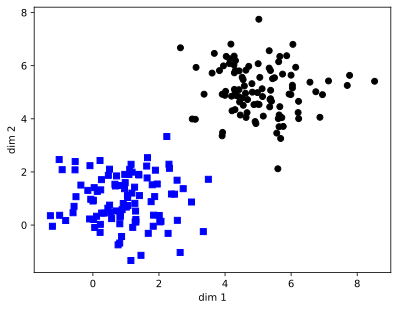

In [7]:
nperclust = 100
blur =1 #--> acts as standard deviation
A=[1,1]  #-->acts as mean/centre for data. data will be generated around these
B=[5,1]

a = [A[0] + np.random.randn(nperclust)*blur, A[0] + np.random.randn(nperclust)*blur]
b = [B[0] + np.random.randn(nperclust)*blur, B[0] + np.random.randn(nperclust)*blur]

labels_np = np.vstack((np.zeros((nperclust,1)), np.ones((nperclust,1))))

data_np = np.hstack((a,b)).T

data = torch.tensor(data_np).float()
label = torch.tensor(labels_np).float()

fig = plt.Figure(figsize=(5,5))
plt.plot(data[np.where(label==0)[0],0], data[np.where(label==0)[0],1], 'bs')
plt.plot(data[np.where(label==1)[0],0], data[np.where(label==1)[0],1], 'ko')
plt.title('')
plt.xlabel('dim 1')
plt.ylabel('dim 2')
plt.show()

In [8]:
ANNclassify = nn.Sequential(
    nn.Linear(2,1),
    nn.ReLU(),
    nn.Linear(1,1),
    nn.Sigmoid()
)

ANNclassify

Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
  (1): ReLU()
  (2): Linear(in_features=1, out_features=1, bias=True)
  (3): Sigmoid()
)

In [9]:
lr = .01
lossfunc = nn.BCELoss()

optimizer = torch.optim.SGD(ANNclassify.parameters(), lr = lr)


In [10]:
numepochs = 1000
losses = torch.zeros(numepochs)

for epochi in range(numepochs):
    y_hat = ANNclassify(data)
    loss = lossfunc(y_hat, label)
    losses[epochi] = loss
    #back propogation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

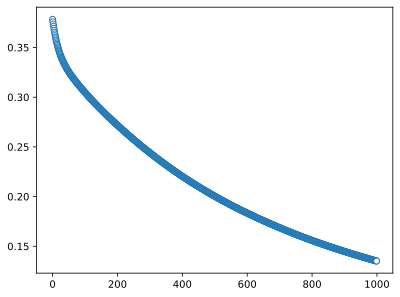

In [13]:
plt.plot(losses.detach(),'o', markerfacecolor='w')
plt.show()

In [14]:
predictions = ANNclassify(data)
predlabels = predictions > .5
misclassified = np.where(predlabels != label)[0]
totalacc = 100-100*len(misclassified)/(2*nperclust)
print(totalacc)

99.0


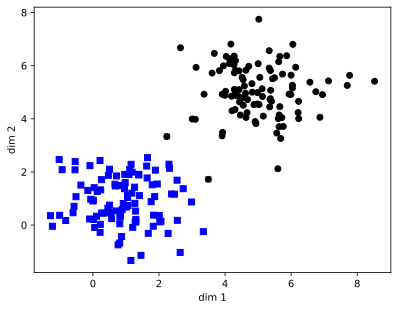

In [ ]:
fig = plt.Figure(figsize=(5,5))
plt.plot(data[misclassified,0], data[misclassified,1], 'rx', markersize=12)
plt.plot(data[np.where(predlabels==0)[0],0], data[np.where(predlabels==0)[0],1], 'bs')
plt.plot(data[np.where(predlabels==1)[0],0], data[np.where(predlabels==1)[0],1], 'ko')
plt.title('')
plt.xlabel('dim 1')
plt.ylabel('dim 2')
plt.show()